<a href="https://colab.research.google.com/github/KenNicholas/komparatif-genai/blob/main/komparatif_genai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup dan Import Awal


In [25]:
# import
import torch, numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

print('pytorch:', torch.__version__)
print('gpu:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

pytorch: 2.14.1+cu130
gpu: Tesla T4


## Load dataset FashionMNIST

In [26]:
tf = transforms.Compose([transforms.ToTensor()])
train_full = datasets.FashionMNIST(root='./data', train=True, download=True, transform=tf)
test_full = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

print('Train: ', len(train_full))
print('Test: ', len(test_full))

Train:  60000
Test:  10000


In [27]:
x = np.concatenate([
    np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
    np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
], axis=0)

y = np.concatenate([
    np.array([train_full[i][1] for i in range(len(train_full))]),
    np.array([test_full[i][1]  for i in range(len(test_full))])
], axis=0)

print('Digabung: ')
print('Total: ', len(x))
print('Classes: ', train_full.classes)

Digabung: 
Total:  70000
Classes:  ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## EDA

In [28]:
from collections import Counter

counts = Counter(y.tolist())

for i in sorted(counts):
  print(f'{i:2d} {train_full.classes[i]:12s} {counts[i]}')

 0 T-shirt/top  7000
 1 Trouser      7000
 2 Pullover     7000
 3 Dress        7000
 4 Coat         7000
 5 Sandal       7000
 6 Shirt        7000
 7 Sneaker      7000
 8 Bag          7000
 9 Ankle boot   7000


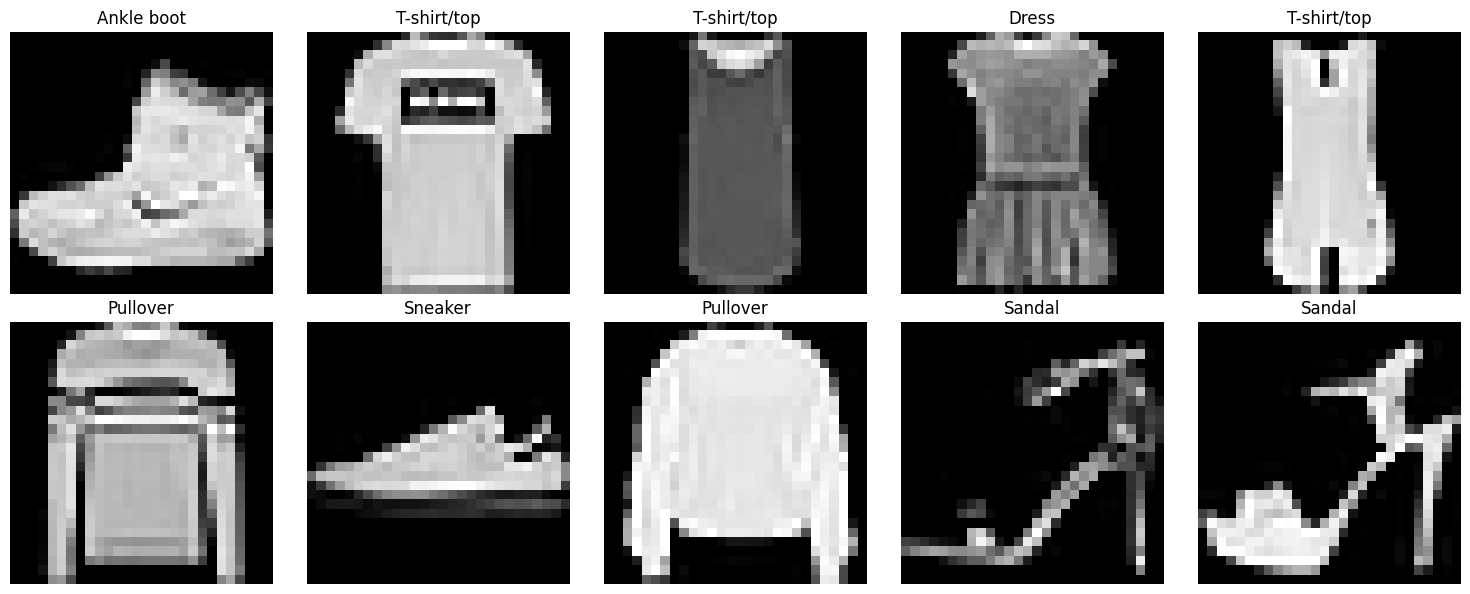

In [29]:
fig, axes = plt.subplots(2, 5, figsize=(15,6))

for ax,i in zip(axes.flat, range(10)):
  img, label = train_full[i]
  ax.imshow(img.squeeze(), cmap='gray')
  ax.set_title(train_full.classes[label])
  ax.axis('off')

plt.tight_layout()
plt.show()

## Train test split (80/10/10)

In [30]:
from sklearn.model_selection import train_test_split

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [31]:
train_set = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
val_set = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
test_set = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

print('Train: ', len(train_set))
print('Validation: ', len(val_set))
print('Test: ', len(test_set))

Train:  56000
Validation:  7000
Test:  7000


## Dataloader

In [32]:
train = DataLoader(train_set, batch_size=128, shuffle=True)
val = DataLoader(val_set,   batch_size=128, shuffle=False)
test = DataLoader(test_set,  batch_size=128, shuffle=False)

## simpan utils.py dan data.py

In [34]:
!mkdir -p src

In [35]:
%%writefile src/utils.py
import torch, numpy as np, random, json, os

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def get_device():
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Writing src/utils.py


In [36]:
%%writefile src/data.py
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

def get_loaders(batch_size=128, seed=42):
    tf = transforms.Compose([transforms.ToTensor()])
    train_full = datasets.FashionMNIST(root='./data', train=True,  download=True, transform=tf)
    test_full  = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

    X_all = np.concatenate([
        np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
        np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
    ], axis=0)
    y_all = np.concatenate([
        np.array([train_full[i][1] for i in range(len(train_full))]),
        np.array([test_full[i][1]  for i in range(len(test_full))])
    ], axis=0)

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=seed, stratify=y_temp)

    train_set = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    val_set   = TensorDataset(torch.from_numpy(X_val),   torch.from_numpy(y_val))
    test_set  = TensorDataset(torch.from_numpy(X_test),  torch.from_numpy(y_test))

    return (DataLoader(train_set, batch_size=batch_size, shuffle=True),
            DataLoader(val_set,   batch_size=batch_size, shuffle=False),
            DataLoader(test_set,  batch_size=batch_size, shuffle=False))

Writing src/data.py
